# 実験結果の可視化
`outputs/` を再帰的に走査し，同一条件の全seedの結果から平均と標準偏差を計算して可視化する．図と表は各実験のディレクトリに保存する．

In [1]:
import glob
import json
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

matplotlib.rcParams["font.size"] = 9
OUTPUT_DIR = "outputs"

# ===== 可視化する対象の選択（変数を書き換えて選ぶ） =====
EX001 = "ex001_coco_val500_image_word"
EX001_METHODS = ["ResNet50-IN1k", "CLIP-RN50", "CLIP-ViT-B32"]
EX001_PANELS = [("A", "P@1"), ("A", "R@5"), ("B", "P@1"), ("B", "R@5")]  # 論文の図2に対応
EX002 = "ex002_coco_4img_class_agnostic_det"
EX003 = "ex003_coco_val500_pipeline"
EX003_METHODS = ["CLIP-ViT-B32", "CLIP-RN50", "ResNet50-IN1k"]
EX003_DEPTH_CONDITIONS = [("CLIP-ViT-B32", "detr_threshold0.97_crop_pad"), ("CLIP-ViT-B32", "detr_threshold0.9_crop_center")]

## 共通関数

In [2]:
def collect_metrics(experiment):
    """
    実験ディレクトリ以下の metrics.json を走査し，(手法, 条件) ごとにseed間の平均と標準偏差を集計する．

    Args:
        experiment (str): 実験ディレクトリ名．

    Returns:
        pd.DataFrame: 列 method, condition, metric, mean, std, n_seeds．
    """
    rows = []
    for path in glob.glob(os.path.join(OUTPUT_DIR, experiment, "*", "*", "*", "metrics.json")):
        method, condition, seed = path.split(os.sep)[-4:-1]
        for metric, value in json.load(open(path)).items():
            value = value["mean"] if isinstance(value, dict) else value
            rows.append({"method": method, "condition": condition, "seed": seed, "metric": metric, "value": value})
    df = pd.DataFrame(rows)
    return (df.groupby(["method", "condition", "metric"])["value"]
              .agg(mean="mean", std="std", n_seeds="size").reset_index().fillna({"std": 0.0}))


def load_seed_files(experiment, method, condition, file_name):
    """
    1条件の全seedのファイルパスを返す．

    Args:
        experiment (str): 実験ディレクトリ名．
        method (str): 手法名．
        condition (str): 条件名．
        file_name (str): ファイル名．

    Returns:
        list[str]: ファイルパスのリスト．
    """
    return sorted(glob.glob(os.path.join(OUTPUT_DIR, experiment, method, condition, "*", file_name)))

## ex001：ResNet50-IN1k vs CLIP（論文の表1，表2，図2）
誤差棒は画像単位のブートストラップ95%信頼区間（seedが複数ある場合はseed間で平均）．

P@1    R@1    P@5    R@5  paper P@1  paper R@1  \
condition method                                                            
A         ResNet50-IN1k  0.216  0.091  0.069  0.123      0.255      0.095   
          CLIP-RN50      0.855  0.431  0.316  0.659      0.838      0.397   
          CLIP-ViT-B32   0.855  0.433  0.328  0.687      0.822      0.385   
B         ResNet50-IN1k  0.294  0.024  0.100  0.041      0.350      0.027   
          CLIP-RN50      0.528  0.045  0.334  0.139      0.454      0.035   
          CLIP-ViT-B32   0.534  0.045  0.352  0.148      0.444      0.035   

                         paper P@5  paper R@5  
condition method                               
A         ResNet50-IN1k      0.084      0.132  
          CLIP-RN50          0.334      0.649  
          CLIP-ViT-B32       0.350      0.678  
B         ResNet50-IN1k      0.104      0.040  
          CLIP-RN50          0.306      0.118  
          CLIP-ViT-B32       0.313      0.121

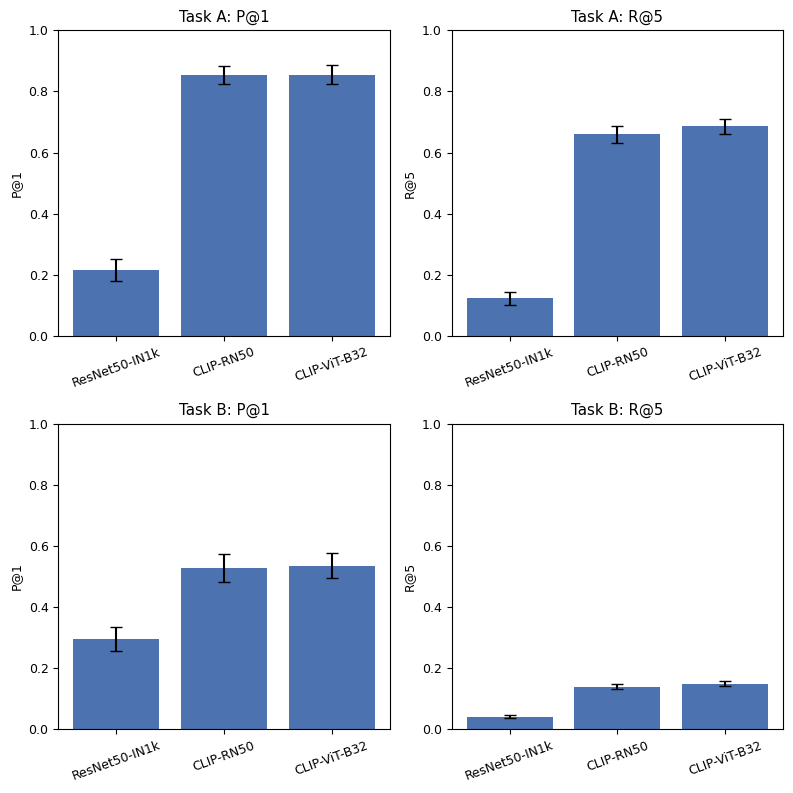

task                               A                                       B  \
metric                           P@1       P@5       R@1       R@5       P@1   
method_a      method_b                                                         
CLIP-RN50     CLIP-ViT-B32  1.00e+00  3.76e-02  7.23e-01  6.30e-04  8.02e-01   
ResNet50-IN1k CLIP-RN50     5.00e-65  3.75e-74  9.91e-52  2.10e-71  1.38e-14   
              CLIP-ViT-B32  2.11e-65  3.21e-74  7.20e-53  2.22e-72  8.02e-16   

task                                                      
metric                           P@5       R@1       R@5  
method_a      method_b                                    
CLIP-RN50     CLIP-ViT-B32  2.83e-03  5.36e-01  5.88e-03  
ResNet50-IN1k CLIP-RN50     1.76e-58  2.23e-12  7.08e-56  
              CLIP-ViT-B32  3.10e-62  2.22e-12  2.43e-59

In [3]:
def ex001_table():
    """
    ex001の指標を手法×タスクの表にまとめ，論文値と並べて保存する．

    Returns:
        pd.DataFrame: 手法・タスクごとの P@1, R@1, P@5, R@5．
    """
    df = collect_metrics(EX001)
    table = df.pivot_table(index=["condition", "method"], columns="metric", values="mean").round(3)
    table = table.reindex([(t, m) for t in ["A", "B"] for m in EX001_METHODS])[["P@1", "R@1", "P@5", "R@5"]]
    paper = pd.DataFrame([[0.255, 0.095, 0.084, 0.132], [0.838, 0.397, 0.334, 0.649], [0.822, 0.385, 0.350, 0.678],
                          [0.350, 0.027, 0.104, 0.040], [0.454, 0.035, 0.306, 0.118], [0.444, 0.035, 0.313, 0.121]],
                         index=table.index, columns=[f"paper {c}" for c in table.columns])
    table = pd.concat([table, paper], axis=1)
    table.to_csv(os.path.join(OUTPUT_DIR, EX001, "table_metrics.csv"))
    return table


def ex001_figure():
    """
    論文の図2に対応する4パネルの棒グラフ（誤差棒はブートストラップ95%CI）を保存する．

    Returns:
        None
    """
    fig, axes = plt.subplots(2, 2, figsize=(8, 8))
    for ax, (task, metric) in zip(axes.flat, EX001_PANELS):
        means, errs = [], []
        for method in EX001_METHODS:
            ms = [json.load(open(p))[metric] for p in load_seed_files(EX001, method, task, "metrics.json")]
            mean = np.mean([m["mean"] for m in ms])
            means.append(mean)
            errs.append([mean - np.mean([m["ci_low"] for m in ms]), np.mean([m["ci_high"] for m in ms]) - mean])
        ax.bar(EX001_METHODS, means, yerr=np.array(errs).T, capsize=4, color="#4C72B0")
        ax.set_ylim(0, 1)
        ax.set_title(f"Task {task}: {metric}")
        ax.set_ylabel(metric)
        ax.tick_params(axis="x", rotation=20)
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, EX001, "fig_metrics_comparison.png"), dpi=150)
    plt.show()


display(ex001_table())
ex001_figure()
wil = pd.DataFrame(json.load(open(glob.glob(os.path.join(OUTPUT_DIR, EX001, "wilcoxon_seed*.json"))[0])))
wil["p_value"] = wil["p_value"].map(lambda p: f"{p:.2e}")
wil.to_csv(os.path.join(OUTPUT_DIR, EX001, "table_wilcoxon.csv"), index=False)
display(wil.pivot_table(index=["method_a", "method_b"], columns=["task", "metric"], values="p_value", aggfunc="first"))

## ex002：物体領域検出モデルの比較（論文の表3）

metric                                               mean_proposals  \
method         condition                                              
DETR           threshold0.5                                    2.25   
               threshold0.7                                    1.75   
               threshold0.9                                    1.50   
Grounding_DINO box_threshold0.35_text_threshold0.25            1.50   
OWL-ViT        threshold0.1                                    1.50   

metric                                               recall_iou0.5  \
method         condition                                             
DETR           threshold0.5                                    0.8   
               threshold0.7                                    0.7   
               threshold0.9                                    0.6   
Grounding_DINO box_threshold0.35_text_threshold0.25            0.5   
OWL-ViT        threshold0.1                                    0.5   

metric                                               mean_best_iou  
method         condition                                            
DETR           threshold0.5                                  0.705  
               threshold0.7                                  0.669  
               threshold0.9                                  0.583  
Grounding_DINO box_threshold0.35_text_threshold0.25          0.546  
OWL-ViT        threshold0.1                                  0.517

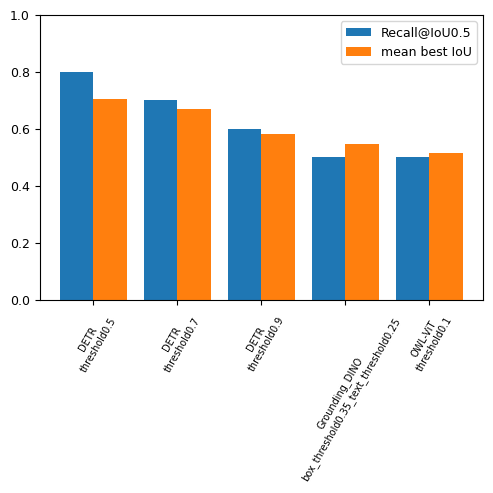

In [4]:
df = collect_metrics(EX002)
table = df.pivot_table(index=["method", "condition"], columns="metric", values="mean")[["mean_proposals", "recall_iou0.5", "mean_best_iou"]].round(3)
table.to_csv(os.path.join(OUTPUT_DIR, EX002, "table_detectors.csv"))
display(table)
fig, ax = plt.subplots(figsize=(5, 5))
labels = [f"{m}\n{c}" for m, c in table.index]
x = np.arange(len(table))
ax.bar(x - 0.2, table["recall_iou0.5"], 0.4, label="Recall@IoU0.5")
ax.bar(x + 0.2, table["mean_best_iou"], 0.4, label="mean best IoU")
ax.set_xticks(x, labels, rotation=60, fontsize=7)
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, EX002, "fig_detectors.png"), dpi=150)
plt.show()

## ex003：パイプライン全体のカテゴリアノテーション精度（論文4.4節）

metric                                        n_instances  n_detections  \
method        condition                                                   
CLIP-RN50     detr_threshold0.5_crop_center        2343.0        5106.0   
              detr_threshold0.5_crop_pad           2343.0        5106.0   
              detr_threshold0.7_crop_center        2217.0        3881.0   
              detr_threshold0.7_crop_pad           2217.0        3881.0   
              detr_threshold0.97_crop_center       1519.0        1679.0   
              detr_threshold0.97_crop_pad          1519.0        1679.0   
              detr_threshold0.9_crop_center        1892.0        2476.0   
              detr_threshold0.9_crop_pad           1892.0        2476.0   
CLIP-ViT-B32  detr_threshold0.5_crop_center        2343.0        5106.0   
              detr_threshold0.5_crop_pad           2343.0        5106.0   
              detr_threshold0.7_crop_center        2217.0        3881.0   
              detr_threshold0.7_crop_pad           2217.0        3881.0   
              detr_threshold0.97_crop_center       1519.0        1679.0   
              detr_threshold0.97_crop_pad          1519.0        1679.0   
              detr_threshold0.9_crop_center        1892.0        2476.0   
              detr_threshold0.9_crop_pad           1892.0        2476.0   
ResNet50-IN1k detr_threshold0.5_crop_center        2343.0        5106.0   
              detr_threshold0.5_crop_pad           2343.0        5106.0   
              detr_threshold0.7_crop_center        2217.0        3881.0   
              detr_threshold0.7_crop_pad           2217.0        3881.0   
              detr_threshold0.97_crop_center       1519.0        1679.0   
              detr_threshold0.97_crop_pad          1519.0        1679.0   
              detr_threshold0.9_crop_center        1892.0        2476.0   
              detr_threshold0.9_crop_pad           1892.0        2476.0   

metric                                        top1_accuracy  top5_accuracy  
method        condition                                                     
CLIP-RN50     detr_threshold0.5_crop_center           0.367          0.649  
              detr_threshold0.5_crop_pad              0.460          0.740  
              detr_threshold0.7_crop_center           0.371          0.655  
              detr_threshold0.7_crop_pad              0.467          0.747  
              detr_threshold0.97_crop_center          0.408          0.709  
              detr_threshold0.97_crop_pad             0.512          0.808  
              detr_threshold0.9_crop_center           0.389          0.681  
              detr_threshold0.9_crop_pad              0.484          0.776  
CLIP-ViT-B32  detr_threshold0.5_crop_center           0.481          0.778  
              detr_threshold0.5_crop_pad              0.560          0.855  
              detr_threshold0.7_crop_center           0.488          0.783  
              detr_threshold0.7_crop_pad              0.568          0.858  
              detr_threshold0.97_crop_center          0.525          0.830  
              detr_threshold0.97_crop_pad             0.604          0.894  
              detr_threshold0.9_crop_center           0.506          0.804  
              detr_threshold0.9_crop_pad              0.587          0.874  
ResNet50-IN1k detr_threshold0.5_crop_center           0.080          0.111  
              detr_threshold0.5_crop_pad              0.088          0.113  
              detr_threshold0.7_crop_center           0.081          0.110  
              detr_threshold0.7_crop_pad              0.088          0.112  
              detr_threshold0.97_crop_center          0.084          0.113  
              detr_threshold0.97_crop_pad             0.091          0.113  
              detr_threshold0.9_crop_center           0.082          0.112  
              detr_threshold0.9_crop_pad              0.090          0.113

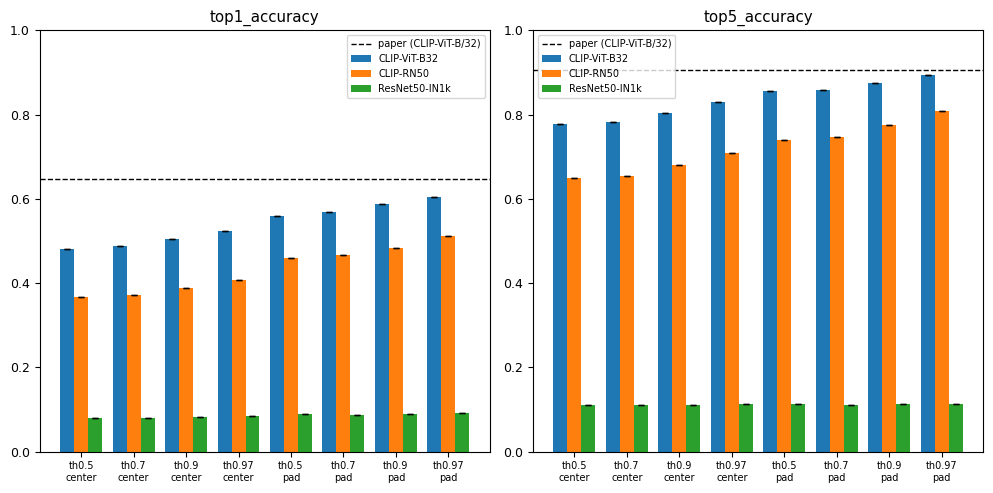

In [5]:
df = collect_metrics(EX003)
table = df.pivot_table(index=["method", "condition"], columns="metric", values="mean")[["n_instances", "n_detections", "top1_accuracy", "top5_accuracy"]]
table = table.round(3)
table.to_csv(os.path.join(OUTPUT_DIR, EX003, "table_pipeline_accuracy.csv"))
display(table)

conditions = sorted(df["condition"].unique(), key=lambda c: (c.split("_crop_")[1], float(c.split("threshold")[1].split("_")[0])))
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, metric in zip(axes, ["top1_accuracy", "top5_accuracy"]):
    width = 0.8 / len(EX003_METHODS)
    for i, method in enumerate(EX003_METHODS):
        sub = df[(df.method == method) & (df.metric == metric)].set_index("condition").reindex(conditions)
        ax.bar(np.arange(len(conditions)) + i * width, sub["mean"], width, yerr=sub["std"], capsize=2, label=method)
    ax.axhline({"top1_accuracy": 0.647, "top5_accuracy": 0.907}[metric], color="k", ls="--", lw=1, label="paper (CLIP-ViT-B/32)")
    ax.set_xticks(np.arange(len(conditions)) + 0.4 - width / 2, [c.replace("detr_threshold", "th").replace("_crop_", "\n") for c in conditions], fontsize=7)
    ax.set_ylim(0, 1)
    ax.set_title(metric)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, EX003, "fig_pipeline_accuracy.png"), dpi=150)
plt.show()

## ex003：WordNet階層の深さごとの確信度（論文の表4，図3）

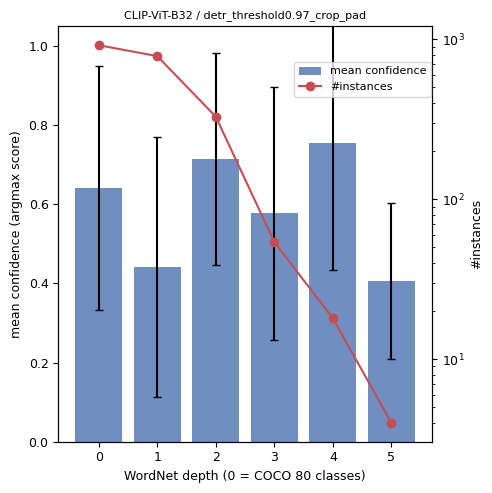

,n_instances,mean_candidates,mean_conf,std_conf,paper n_instances,paper mean_candidates,paper mean_conf
0,917.0,80.000,0.642,0.308,948,80.0,0.695
1,784.0,108.773,0.442,0.328,854,137.2,0.477
2,328.0,6.232,0.715,0.268,305,6.4,0.723
3,54.0,14.537,0.577,0.320,54,11.3,0.586
4,18.0,5.722,0.755,0.321,10,6.9,0.710
5,4.0,10.750,0.406,0.198,1,3.0,0.729
6,NaN,NaN,NaN,NaN,1,1.0,1.000


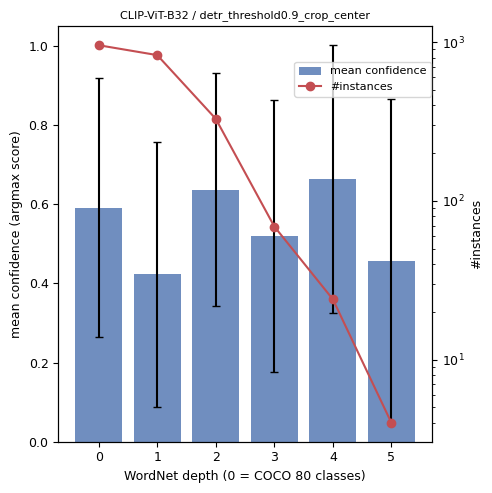

,n_instances,mean_candidates,mean_conf,std_conf,paper n_instances,paper mean_candidates,paper mean_conf
0,957.0,80.000,0.592,0.328,948,80.0,0.695
1,829.0,124.934,0.423,0.334,854,137.2,0.477
2,329.0,7.818,0.637,0.294,305,6.4,0.723
3,69.0,15.464,0.520,0.345,54,11.3,0.586
4,24.0,7.458,0.664,0.338,10,6.9,0.710
5,4.0,13.500,0.457,0.409,1,3.0,0.729
6,NaN,NaN,NaN,NaN,1,1.0,1.000


In [6]:
def depth_figure(method, condition):
    """
    深さごとの平均確信度（棒，左軸）とインスタンス数（折れ線，右軸，対数）を描画し保存する．

    Args:
        method (str): VLM名．
        condition (str): 条件名．

    Returns:
        pd.DataFrame: seed間で平均した深さごとの統計．
    """
    stats = pd.concat([pd.read_csv(p) for p in load_seed_files(EX003, method, condition, "depth_stats.csv")])
    stats = stats.groupby("depth").mean().round(3)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.bar(stats.index, stats["mean_conf"], yerr=stats["std_conf"], capsize=3, color="#4C72B0", alpha=0.8, label="mean confidence")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("WordNet depth (0 = COCO 80 classes)")
    ax.set_ylabel("mean confidence (argmax score)")
    ax2 = ax.twinx()
    ax2.plot(stats.index, stats["n_instances"], "o-", color="#C44E52", label="#instances")
    ax2.set_yscale("log")
    ax2.set_ylabel("#instances")
    ax.set_title(f"{method} / {condition}", fontsize=8)
    fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88), fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, EX003, method, condition, "fig_depth_confidence.png"), dpi=150)
    plt.show()
    return stats


paper = pd.DataFrame({"paper n_instances": [948, 854, 305, 54, 10, 1, 1], "paper mean_candidates": [80.0, 137.2, 6.4, 11.3, 6.9, 3.0, 1.0],
                      "paper mean_conf": [0.695, 0.477, 0.723, 0.586, 0.710, 0.729, 1.000]})
for method, condition in EX003_DEPTH_CONDITIONS:
    stats = depth_figure(method, condition)
    table = pd.concat([stats[["n_instances", "mean_candidates", "mean_conf", "std_conf"]], paper], axis=1)
    table.to_csv(os.path.join(OUTPUT_DIR, EX003, method, condition, "table_depth.csv"))
    display(table)

## ex005：YOLOとの比較（order_003）
YOLOは自身の語彙（COCOの80クラス）で評価する．提案手法はex003のCLIP-ViT-B/32（pad）の結果を用いる．

metric                                                    n_instances  \
proposed (DETR+CLIP-ViT-B32) detr_threshold0.5_crop_pad        2343.0   
                             detr_threshold0.97_crop_pad       1519.0   
yolo11m                      coco500_conf0.25                  2115.0   
                             coco500_conf0.5                   1699.0   
                             coco500_conf0.7                   1314.0   
yolo11n                      coco500_conf0.25                  1717.0   
                             coco500_conf0.5                   1278.0   
                             coco500_conf0.7                    904.0   
yolo11x                      coco500_conf0.25                  2210.0   
                             coco500_conf0.5                   1832.0   
                             coco500_conf0.7                   1474.0   
yolo11x+CLIP-ViT-B32         coco500_conf0.25                  2210.0   
                             coco500_conf0.5                   1832.0   
                             coco500_conf0.7                   1474.0   
yolov8x                      coco500_conf0.25                  2220.0   
                             coco500_conf0.5                   1844.0   
                             coco500_conf0.7                   1467.0   

metric                                                    top1_accuracy  \
proposed (DETR+CLIP-ViT-B32) detr_threshold0.5_crop_pad           0.560   
                             detr_threshold0.97_crop_pad          0.604   
yolo11m                      coco500_conf0.25                     0.976   
                             coco500_conf0.5                      0.985   
                             coco500_conf0.7                      0.992   
yolo11n                      coco500_conf0.25                     0.957   
                             coco500_conf0.5                      0.970   
                             coco500_conf0.7                      0.987   
yolo11x                      coco500_conf0.25                     0.981   
                             coco500_conf0.5                      0.985   
                             coco500_conf0.7                      0.993   
yolo11x+CLIP-ViT-B32         coco500_conf0.25                     0.565   
                             coco500_conf0.5                      0.589   
                             coco500_conf0.7                      0.604   
yolov8x                      coco500_conf0.25                     0.971   
                             coco500_conf0.5                      0.984   
                             coco500_conf0.7                      0.987   

metric                                                    top5_accuracy  \
proposed (DETR+CLIP-ViT-B32) detr_threshold0.5_crop_pad           0.855   
                             detr_threshold0.97_crop_pad          0.894   
yolo11m                      coco500_conf0.25                     0.998   
                             coco500_conf0.5                      0.999   
                             coco500_conf0.7                      0.999   
yolo11n                      coco500_conf0.25                     0.996   
                             coco500_conf0.5                      0.996   
                             coco500_conf0.7                      0.997   
yolo11x                      coco500_conf0.25                     0.999   
                             coco500_conf0.5                      0.998   
                             coco500_conf0.7                      0.997   
yolo11x+CLIP-ViT-B32         coco500_conf0.25                     0.860   
                             coco500_conf0.5                      0.889   
                             coco500_conf0.7                      0.907   
yolov8x                      coco500_conf0.25                     0.999   
                             coco500_conf0.5                      0.999   
                             coco500_conf0.7               

,method,condition,proposed,n_common,yolo_top1,proposed_top1,mcnemar_p,yolo_top1_person,proposed_top1_person
5,yolo11m,coco500_conf0.25,detr_threshold0.5_crop_pad,1971,0.978184,0.584982,4.458158e-208,1.000000,0.402496
3,yolo11m,coco500_conf0.5,detr_threshold0.5_crop_pad,1630,0.985276,0.601840,7.403526e-177,0.998145,0.369202
1,yolo11m,coco500_conf0.7,detr_threshold0.5_crop_pad,1291,0.993029,0.627421,1.411215e-135,1.000000,0.333333
17,yolo11n,coco500_conf0.25,detr_threshold0.5_crop_pad,1656,0.964372,0.603865,4.002513e-151,0.991438,0.381849
15,yolo11n,coco500_conf0.5,detr_threshold0.5_crop_pad,1264,0.973101,0.620253,7.310225e-115,0.995662,0.344902
13,yolo11n,coco500_conf0.7,detr_threshold0.5_crop_pad,899,0.987764,0.617353,8.054323e-91,0.997143,0.285714
11,yolo11x,coco500_conf0.25,detr_threshold0.5_crop_pad,2015,0.983623,0.586104,5.962934e-219,0.998498,0.406907
9,yolo11x,coco500_conf0.5,detr_threshold0.5_crop_pad,1742,0.986223,0.598737,1.999168e-185,1.000000,0.377816
7,yolo11x,coco500_conf0.7,detr_threshold0.5_crop_pad,1429,0.994402,0.615815,2.583714e-159,1.000000,0.338330
23,yolov8x,coco500_conf0.25,detr_threshold0.5_crop_pad,2027,0.978293,0.579674,5.287981e-221,0.998516,0.408012


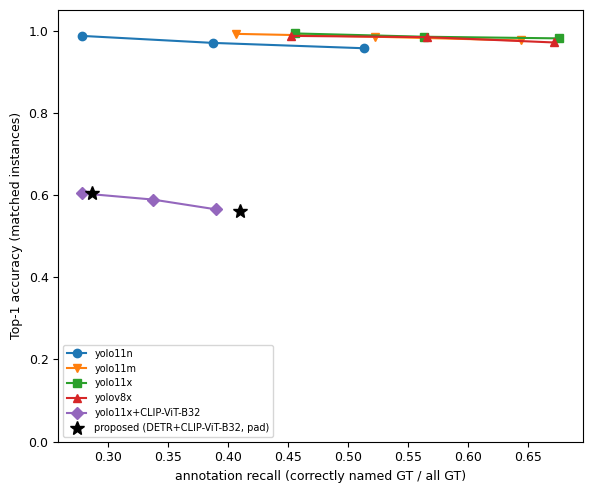

metric                 mean_best_iou  mean_proposals  recall_iou0.5
method  condition                                                  
yolo11m loc4_conf0.25          0.668            2.00            0.7
        loc4_conf0.5           0.487            1.25            0.5
        loc4_conf0.7           0.487            1.25            0.5
yolo11n loc4_conf0.25          0.569            1.50            0.6
        loc4_conf0.5           0.488            1.25            0.5
        loc4_conf0.7           0.488            1.25            0.5
yolo11x loc4_conf0.25          0.719            2.25            0.7
        loc4_conf0.5           0.536            1.50            0.5
        loc4_conf0.7           0.489            1.25            0.5
yolov8x loc4_conf0.25          0.767            2.25            0.8
        loc4_conf0.5           0.578            1.50            0.6
        loc4_conf0.7           0.487            1.25            0.5

In [7]:
EX005 = "ex005_coco_val500_yolo_comparison"
EX005_METHODS = ["yolo11n", "yolo11m", "yolo11x", "yolov8x", "yolo11x+CLIP-ViT-B32"]
EX005_PROPOSED = ["detr_threshold0.5_crop_pad", "detr_threshold0.97_crop_pad"]


def ex005_table():
    """
    YOLOと提案手法のカテゴリアノテーション精度を1つの表にまとめて保存する．

    Returns:
        pd.DataFrame: 手法・条件ごとの n_instances，top1_accuracy，top5_accuracy，annotation_recall．
    """
    df = collect_metrics(EX005)
    df = df[df.condition.str.startswith("coco500")]
    table = df.pivot_table(index=["method", "condition"], columns="metric", values="mean")
    prop = collect_metrics(EX003)
    prop = prop[(prop.method == "CLIP-ViT-B32") & prop.condition.isin(EX005_PROPOSED)]
    prop = prop.pivot_table(index=["method", "condition"], columns="metric", values="mean")
    prop["annotation_recall"] = prop["top1_accuracy"] * prop["n_instances"] / prop["n_gt"]
    prop.index = pd.MultiIndex.from_tuples([("proposed (DETR+CLIP-ViT-B32)", c) for _, c in prop.index])
    table = pd.concat([prop, table])[["n_instances", "top1_accuracy", "top5_accuracy", "annotation_recall"]].round(3)
    table.to_csv(os.path.join(OUTPUT_DIR, EX005, "table_yolo_comparison.csv"))
    return table


def ex005_common_table():
    """
    共通GTインスタンスでの比較結果（McNemar検定）を表にまとめて保存する．

    Returns:
        pd.DataFrame: YOLOの条件 × 提案手法の条件ごとの比較結果．
    """
    rows = []
    for path in glob.glob(os.path.join(OUTPUT_DIR, EX005, "*", "coco500_*", "*", "common_vs_*.json")):
        method, condition = path.split(os.sep)[-4:-2]
        ref = os.path.basename(path)[len("common_vs_"):-len(".json")]
        rows.append({"method": method, "condition": condition, "proposed": ref, **json.load(open(path))})
    table = pd.DataFrame(rows).sort_values(["proposed", "method", "condition"])
    table.to_csv(os.path.join(OUTPUT_DIR, EX005, "table_common_mcnemar.csv"), index=False)
    return table


table = ex005_table()
display(table)
display(ex005_common_table()[["method", "condition", "proposed", "n_common", "yolo_top1", "proposed_top1", "mcnemar_p",
                              "yolo_top1_person", "proposed_top1_person"]])

fig, ax = plt.subplots(figsize=(6, 5))
for method, marker in zip(["yolo11n", "yolo11m", "yolo11x", "yolov8x", "yolo11x+CLIP-ViT-B32"], "ovs^D"):
    sub = table.loc[method] if method in table.index.get_level_values(0) else None
    if sub is not None:
        ax.plot(sub["annotation_recall"], sub["top1_accuracy"], marker=marker, label=method)
prop = table.loc["proposed (DETR+CLIP-ViT-B32)"]
ax.plot(prop["annotation_recall"], prop["top1_accuracy"], marker="*", ms=10, ls="none", color="k", label="proposed (DETR+CLIP-ViT-B32, pad)")
ax.set_xlabel("annotation recall (correctly named GT / all GT)")
ax.set_ylabel("Top-1 accuracy (matched instances)")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, EX005, "fig_yolo_comparison.png"), dpi=150)
plt.show()

loc = collect_metrics(EX005)
loc = loc[loc.condition.str.startswith("loc4")].pivot_table(index=["method", "condition"], columns="metric", values="mean").round(3)
loc.to_csv(os.path.join(OUTPUT_DIR, EX005, "table_loc4.csv"))
display(loc)